# Safety! - Avery Bird's Sub-Metric

My sub-metric is safety! The neighborhood with the fewest reported offenses is the safest. My dataset is Monthly Criminal Activity from the WPRDC (Pittsburgh police data, 2024-2026)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

## Loading the data
I load the Monthly Criminal Activity dataset from the WPRDC (Pittsburgh police data, 22024-2026). The file is criminal_activity.csv.

In [10]:
df = pd.read_csv("criminal_activity.csv", low_memory=False)

print(df.shape)
df.head()

(116730, 21)


,_id,Report_Number,ReportedDate,ReportedTime,Hour,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Coded_Offense,NIBRS_Offense_Code,...,NIBRS_Offense_Type,NIBRS_Crime_Against,NIBRS_Offense_Grouping,Violation,XCOORD,YCOORD,Zone,Tract,Neighborhood,Block_Address
0,1,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,13A AGGRAVATED ASSAULT,13A,...,Aggravated Assault,Person,A,18 2718 A1 Strangulation Basic - Applying,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
1,2,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,13C INTIMIDATION,13C,...,Intimidation,Person,A,18 2706 A1 Terroristic Threats-General,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
2,3,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,90Z ALL OTHER OFFENSES,90Z,...,All other Offenses,Group B,B,75 3733 A Fleeing or Attempting To Elude Polic...,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
3,4,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,23H ALL OTHER LARCENY,23H,...,All Other Larceny,Property,A,18 3921 A Theft by Unlawful Taking-Movable – L...,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
4,5,PGHP24000017,2024-01-01,00:21,0,Monday,Jan,2024,9999 Vehicle Offense (Not NIBRS Reportable),999,...,Not NIBRS Reportable,Group B,B,LO 6 101 Discharge of Firearms Prohibited,-80.0243,40.4582,Zone 1,2107,Manchester,"1200 BLOCK OF COLUMBUS AVE PITTSBURGH, PA"


## Check the Neighborhood column
Before counting anything, I check the Neighborhood column looking for problems. For example, rows with no neighborhood and how many different neighborhood names there are.  

In [12]:
print(df['Neighborhood'].isna().sum())
print(df['Neighborhood'].nunique())

1259
92


## Cleaning
1,259 had no neighborhood, so I dropped them. Two of the neighborhoods were written with two different dashes, so I made the dashes match - that merge them into one name each. Since I merged them the neighborhoods went from 92 to 90

In [14]:
df['Neighborhood'] = df['Neighborhood'].str.strip().str.replace('\u2013', '-', regex=False)
df = df.dropna(subset=['Neighborhood'])

print(len(df))
print(df['Neighborhood'].nunique())


115471
90


## Counting offenses per neighborhood
I count how many offense rows each neighborhood has. value_counts() sorts from most to fewest.

In [17]:
counts = df['Neighborhood'].value_counts()

print(counts.head(10))
print(counts.tail(10))

Neighborhood
Central Business District    13283
South Side Flats              8117
Carrick                       4087
East Liberty                  3590
Shadyside                     3489
East Allegheny                3265
Bloomfield                    2620
Mount Washington              2522
Knoxville                     2495
Squirrel Hill South           2444
Name: count, dtype: int64
Neighborhood
Esplen            194
Oakwood           177
Regent Square     176
Summer Hill       138
Swisshelm Park    113
East Carnegie     104
Chartiers City     88
New Homestead      83
St. Clair          63
Ridgemont          56
Name: count, dtype: int64


## The 10 safest neighborhoods

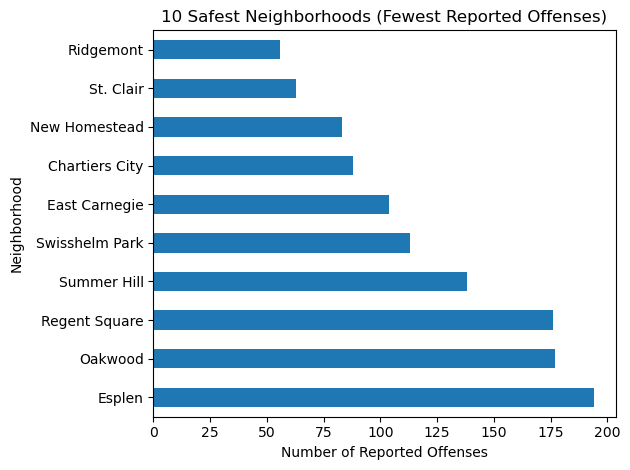

In [23]:
counts.tail(10).plot(kind='barh')
plt.title('10 Safest Neighborhoods (Fewest Reported Offenses)')
plt.xlabel('Number of Reported Offenses')
plt.tight_layout()
plt.show()

## Sanity check: 2025 only
I reran the count on 2025 alone to see whether the same neighborhoods come out safest in a single year.

In [21]:
df_2025 = df[df['ReportedYear'] == 2025]
counts_2025 = df_2025['Neighborhood'].value_counts()

print(counts_2025.tail(10))

Neighborhood
Glen Hazel        62
Esplen            54
Summer Hill       53
East Carnegie     53
Fairywood         50
Swisshelm Park    36
Chartiers City    32
New Homestead     31
Ridgemont         20
St. Clair         10
Name: count, dtype: int64


## Conclussion
Based on the data, Ridgemont, with 56 reported offenses from 2024-2026 is the safest neighborhood in Pittsburgh. Not only did it have the fewest overall but if you look at just the year 2025 alone, the same neighborhoods stay the safest, showing the same small group: St. Clair, Ridgemont, and New Homestead. Although, there is one thing to keep in mind, these are raw counts, not rates, so small residential neighborhoods like Ridgemont have an advantage, while neighborhoods like the Central Business District's 13,283 offenses partially reflect how many people pass through downtown. Personally I think the best neighborhood is Morningside because it has 36 bus stops and only 337 offenses. The reason I bring up bus stops is because typically neighborhoods with more bus stops have higher offenses. However, Morningside has a good amount of bus stops while still being the 19th safest neighborhood in Pittsburgh. 